In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

In [2]:
lake = 'lucerne'
folder_path = rf"/storage/alplakes_test/{lake}_100m_2025"
input_folder = os.path.join(folder_path, "outputs_swirl", "eddy_catalogues_final")

output_folder = r'../../figures/3.1.1'
os.makedirs(output_folder, exist_ok=True)

In [3]:
def set_default_figure_setting():
    plt.rcParams.update({
        "figure.figsize": (10, 2),
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "axes.grid": False,
        "axes.edgecolor": "#8B8B8B",
        "legend.edgecolor": "#8B8B8B",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.minor.visible": False,
        "ytick.minor.visible": False,
    })

set_default_figure_setting()

# Import catalogue

In [4]:
df_lvl0 = pd.read_csv(os.path.join(input_folder, "lvl0.csv"))
df_lvl0 = df_lvl0.set_index('id', drop=False)
df_lvl0['date'] = pd.to_datetime(df_lvl0['date'])
df_lvl0 = df_lvl0[df_lvl0['date'] >= '2025-03-01']

In [5]:
df_lake = pd.read_csv(os.path.join(folder_path, "outputs_swirl_with_iw", "eddy_catalogues_final", "lake_characteristics.csv"))
df_lake = df_lake.set_index('id', drop=False)
df_lake['date'] = pd.to_datetime(df_lake['date'])
df_lake = df_lake[df_lake['date'] >= '2025-03-01']

In [6]:
depths = df_lvl0[['depth_index', 'depth_[m]']].drop_duplicates().sort_values('depth_index').reset_index(drop=True)

# Create xarrays

In [7]:
i_depth_min = 0
i_depth_max = 50
if lake=='lucerne':
    i_depth_max = 45

In [8]:
xr_surface_lake = df_lake[(
        (df_lake['depth_index'] <= i_depth_max) &
        (df_lake['depth_index'] >= i_depth_min) &
        (df_lake['date'] >= '2025-03-01') &
        (df_lake['date'] <= '2026-03-01')
    )].groupby(['date','depth_[m]'])['surface_area_[m2]'].sum().to_xarray()

In [9]:
xr_surface_eddy = df_lvl0[(
        (df_lvl0['depth_index'] <= i_depth_max) &
        (df_lvl0['depth_index'] >= i_depth_min) &
        (df_lvl0['date'] >= '2025-03-01') &
        (df_lvl0['date'] <= '2026-03-01')
    )].groupby(['date','depth_[m]'])['surface_area_[m2]'].sum().to_xarray()

In [10]:
xr_surface_ratio = 100 * xr_surface_eddy / xr_surface_lake

In [11]:
df_lvl0['radius'] = np.sqrt(df_lvl0['surface_area_[m2]']/np.pi)
xr_size_per_depth = df_lvl0[(
        (df_lvl0['depth_index'] <= i_depth_max) &
        (df_lvl0['depth_index'] >= i_depth_min) &
        (df_lvl0['date'] >= '2025-03-01') &
        (df_lvl0['date'] <= '2026-03-01')
    )].groupby(['date','depth_[m]'])['radius'].mean().to_xarray()
xr_size_per_depth = xr_size_per_depth.rename({'depth_[m]': 'Z'})

# Plot

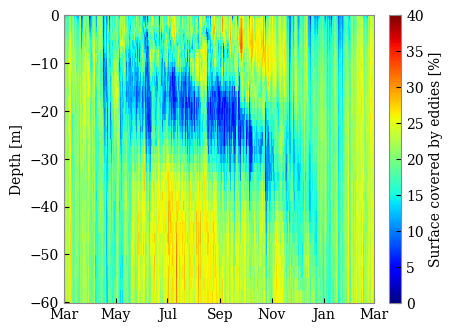

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.set_position([0.18, 0.16, 0.62, 0.72])

pcm = xr_surface_ratio.plot.pcolormesh(
    ax=ax,
    y="depth_[m]",
    cmap="jet",
    vmin=0,
    vmax=40,
    add_colorbar=False,
)


ax.set_xlabel('')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax.set_ylabel("Depth [m]")

cax = fig.add_axes([0.83, 0.16, 0.025, 0.72])
# Colorbar
fig.colorbar(pcm, cax=cax, label="Surface covered by eddies [%]")


In [14]:
import seaborn as sns

In [15]:
cpalette = sns.color_palette('colorblind')
cpalette

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [16]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
seasons_dates = [slice('2025-03-01', '2025-06-01'), slice('2025-06-01', '2025-09-01'), slice('2025-09-01', '2026-01-01'), slice('2026-01-01', '2026-03-01')]
seasons_colors = [cpalette[2], cpalette[8], cpalette[1], cpalette[0]]

### Surface covered by eddies

In [17]:
def display_surf_covered_by_eddies(ax, xr_surface_ratio, seasons, seasons_dates, seasons_colors):
    for season, season_date, season_color in zip(seasons, seasons_dates, seasons_colors):
        xr_surface_ratio.sel(date=season_date).mean(dim='date').plot.line(y="depth_[m]", label=season, ax=ax, color=season_color)

    ax.tick_params(axis='both', which='both', direction='in')
    ax.set_xlabel('Mean surface covered by eddies [%]')
    ax.set_ylabel('Depth [m]')
    ax.legend()


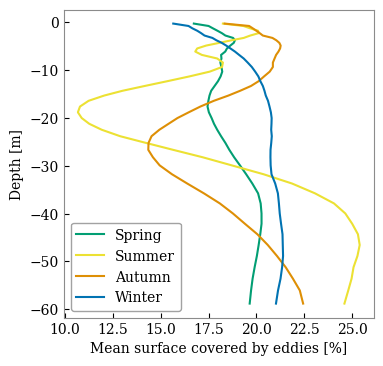

In [18]:
fig, ax = plt.subplots(figsize=(4, 4))
display_surf_covered_by_eddies(ax, xr_surface_ratio, seasons, seasons_dates, seasons_colors)

### Radius

In [19]:
def display_radius_per_depth(ax, xr_size_per_depth, seasons, seasons_dates, seasons_colors):
    for season, season_date, season_color in zip(seasons, seasons_dates, seasons_colors):
        xr_size_per_depth.sel(date=season_date).mean(dim='date').plot(y='Z', label=season, ax=ax, color=season_color)

    ax.tick_params(axis='both', which='both', direction='in')
    ax.set_xlabel('Mean eddy radius [m]')
    ax.set_ylabel('Depth [m]')
    ax.legend()

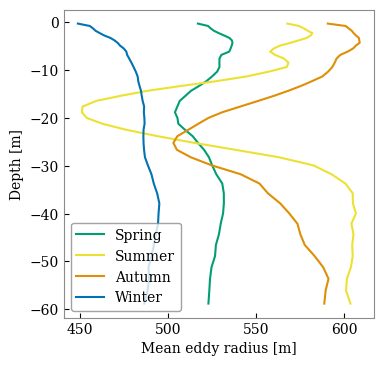

In [20]:
fig, ax = plt.subplots(figsize=(4, 4))
display_radius_per_depth(ax, xr_size_per_depth, seasons, seasons_dates, seasons_colors)

### Rotation direction

In [21]:
xr_clockwise = df_lvl0[(
        (df_lvl0['depth_index'] <= i_depth_max) &
        (df_lvl0['depth_index'] >= i_depth_min) &
        (df_lvl0['date'] >= '2025-03-01') &
        (df_lvl0['date'] <= '2026-03-01') &
        (df_lvl0['rotation_direction'] == 'clockwise')
    )].groupby(['date','depth_[m]'])['rotation_direction'].count().to_xarray()
xr_clockwise = xr_clockwise.rename({'depth_[m]': 'Z'})

xr_counterclockwise = df_lvl0[(
        (df_lvl0['depth_index'] <= i_depth_max) &
        (df_lvl0['depth_index'] >= i_depth_min) &
        (df_lvl0['date'] >= '2025-03-01') &
        (df_lvl0['date'] <= '2026-03-01') &
        (df_lvl0['rotation_direction'] == 'anticlockwise')
    )].groupby(['date','depth_[m]'])['rotation_direction'].count().to_xarray()
xr_counterclockwise = xr_counterclockwise.rename({'depth_[m]': 'Z'})

In [22]:
def display_rot_direction_per_depth(ax, xr_clockwise, xr_counterclockwise, seasons, seasons_dates, seasons_colors):
    for season, season_date, season_color in zip(seasons, seasons_dates, seasons_colors):
        clockwise_number = xr_clockwise.sel(date=season_date).sum(dim='date')
        counterclockwise_number = xr_counterclockwise.sel(date=season_date).sum(dim='date')
        percent_counterclockwise = 100 * counterclockwise_number / (clockwise_number + counterclockwise_number)
        percent_counterclockwise.plot.line(y='Z', label=season, ax=ax, color=season_color)

    ax.set_xlim(32, 68)
    ax.tick_params(axis='both', which='both', direction='in')
    ax.set_xlabel('Percentage of counterclockwise eddies [%]')
    ax.set_ylabel('Depth [m]')

    ax.vlines(x=50, ymin=depths['depth_[m]'].iloc[i_depth_min], ymax=depths['depth_[m]'].iloc[i_depth_max], color='black', linestyle='--', linewidth=1)
    ax.legend()

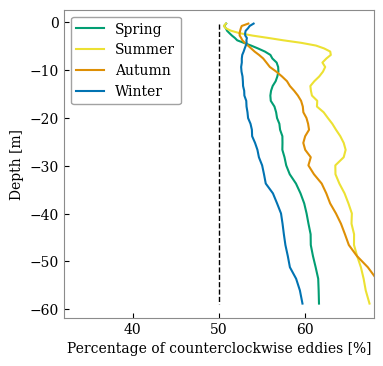

In [23]:
fig, ax = plt.subplots(figsize=(4, 4))
display_rot_direction_per_depth(ax, xr_clockwise, xr_counterclockwise, seasons, seasons_dates, seasons_colors)

# Stacked figures

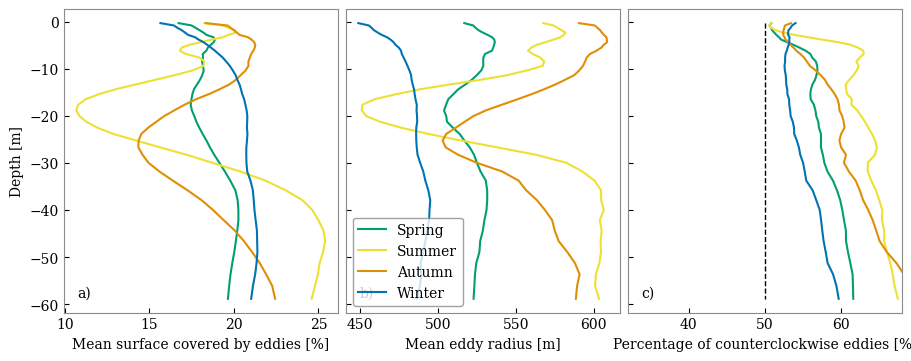

In [24]:
fig, axs = plt.subplots(
    1, 3,
    figsize=(9, 3.5),
    sharey=True,
    layout="constrained",
)

display_surf_covered_by_eddies(axs[0], xr_surface_ratio, seasons, seasons_dates, seasons_colors)
display_radius_per_depth(axs[1], xr_size_per_depth, seasons, seasons_dates, seasons_colors)
display_rot_direction_per_depth(axs[2], xr_clockwise, xr_counterclockwise, seasons, seasons_dates, seasons_colors)

axs[1].set_ylabel('')
axs[2].set_ylabel('')

axs[0].text(0.05, 0.05, f"a)", transform=axs[0].transAxes, ha='left')
axs[1].text(0.05, 0.05, f"b)", transform=axs[1].transAxes, ha='left')
axs[2].text(0.05, 0.05, f"c)", transform=axs[2].transAxes, ha='left')

axs[0].get_legend().remove()
axs[2].get_legend().remove()

plt.show()